<a href="https://colab.research.google.com/github/shabamichael/intro-to-pytorch-tutorial/blob/main/pytorch-tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [246]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
x = torch.rand(5, 3)
print(x)

tensor([[0.7234, 0.2406, 0.4093],
        [0.9738, 0.2052, 0.7404],
        [0.8668, 0.7421, 0.1588],
        [0.6535, 0.0484, 0.2422],
        [0.2096, 0.8402, 0.6172]])


In [247]:
torch.cuda.is_available()


True

In [248]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [249]:
url = 'https://gist.githubusercontent.com/curran/a08a1080b88344b0c8a7/raw/0e7a9b0a5d22642a06d3d5b9bcbad9890c8ee534/iris.csv'
my_df=pd.read_csv(url)
print(my_df)

     sepal_length  sepal_width  petal_length  petal_width    species
0             5.1          3.5           1.4          0.2     setosa
1             4.9          3.0           1.4          0.2     setosa
2             4.7          3.2           1.3          0.2     setosa
3             4.6          3.1           1.5          0.2     setosa
4             5.0          3.6           1.4          0.2     setosa
..            ...          ...           ...          ...        ...
145           6.7          3.0           5.2          2.3  virginica
146           6.3          2.5           5.0          1.9  virginica
147           6.5          3.0           5.2          2.0  virginica
148           6.2          3.4           5.4          2.3  virginica
149           5.9          3.0           5.1          1.8  virginica

[150 rows x 5 columns]


In [250]:
#changed the last column from strings to integer
my_df['species'] = my_df['species'].replace('setosa', 0.0)
my_df['species'] = my_df['species'].replace('versicolor', 1.0)
my_df['species'] = my_df['species'].replace('virginica', 2.0)
print(my_df)

     sepal_length  sepal_width  petal_length  petal_width  species
0             5.1          3.5           1.4          0.2      0.0
1             4.9          3.0           1.4          0.2      0.0
2             4.7          3.2           1.3          0.2      0.0
3             4.6          3.1           1.5          0.2      0.0
4             5.0          3.6           1.4          0.2      0.0
..            ...          ...           ...          ...      ...
145           6.7          3.0           5.2          2.3      2.0
146           6.3          2.5           5.0          1.9      2.0
147           6.5          3.0           5.2          2.0      2.0
148           6.2          3.4           5.4          2.3      2.0
149           5.9          3.0           5.1          1.8      2.0

[150 rows x 5 columns]


/tmp/ipykernel_526/1614300299.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  my_df['species'] = my_df['species'].replace('virginica', 2.0)


In [251]:
# Train , Test and Split! Set X,y
X=my_df.drop('species',axis=1)
y=my_df['species']


In [252]:
# Convert to Numpy arrays
X=X.values
y=y.values

In [253]:
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [254]:
from sklearn.model_selection import train_test_split

In [255]:
# Train  Test Split
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2,random_state=41)

In [256]:
# Convert X features from Numpy array  into float tensors
X_train=torch.FloatTensor(X_train)
X_test=torch.FloatTensor(X_test)

In [257]:
# Convert y labels to tensors long
y_train=torch.LongTensor(y_train)
y_test=torch.LongTensor(y_test)

In [258]:
class Model(nn.Module):
    def __init__(self, in_features=4, h1=8, h2=9, out_features=3):
        super().__init__()
        self.fc1 = nn.Linear(in_features, h1)
        self.fc2 = nn.Linear(h1, h2)
        self.out = nn.Linear(h2, out_features)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.out(x)
        return x

# Initialize the model
torch.manual_seed(41)
model = Model()

In [259]:
# Set the criterion of our model to measure the error, how far off the prdiction are from
# define the loss function to measure models predictions are from the true labels
criterion = nn.CrossEntropyLoss()

#print the model
print(model)


Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)


In [260]:
# choose Optimizer , learning rates lr
# (if error doesnt go down after a bunch of iterations(epoch), then we adjust he learning rate)
# The lower the learning rate the longer it would take to learn and train the model
# model parameters -> Goes through layer1, layer2 and to the ouput for one epoch iteration
# We create bunch of iterations and optimise for each iteration
optimizer =torch.optim.Adam(model.parameters(),lr=0.01)

In [261]:
# Train the Model!
# Determine the number of Epoch required , we send all of our data in one time
# Epoch? (one run thru all the training data in our network)
epoch = 100

# Keep track of our losses, and we want the losses to decrease overtime, so we store our losses in a list
# then we know that the model is learning, so we append our losses to the losses list
losses = []
for i in range(epoch):
    # Go forward and get a prediction
    y_pred = model.forward(X_train) #Get the predicted results

    # Measure the loss / error , It would be high at first
    loss = criterion(y_pred, y_train) # predicted values vs the y_train

    # Keep track of all our losses
    # Detach the losses from python autograd tracking and covert to numpy array
    losses.append(loss.detach().numpy())

    # print every 10 epoch
    if i % 10 == 0:
        print(f"Epoch: {i} and the loss : {loss.item()}")

    # Do some back propagation: take the error rate of the forward propagation and feed it back
    # through the network to tweak its weights, so it can adjust them and learn
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


Epoch: 0 and the loss : 1.1251550912857056
Epoch: 10 and the loss : 1.0096259117126465
Epoch: 20 and the loss : 0.8157405853271484
Epoch: 30 and the loss : 0.585706353187561
Epoch: 40 and the loss : 0.3999636471271515
Epoch: 50 and the loss : 0.2676880657672882
Epoch: 60 and the loss : 0.17942363023757935
Epoch: 70 and the loss : 0.12151690572500229
Epoch: 80 and the loss : 0.0860118418931961
Epoch: 90 and the loss : 0.06520850956439972


Text(0.5, 0, 'epoch')

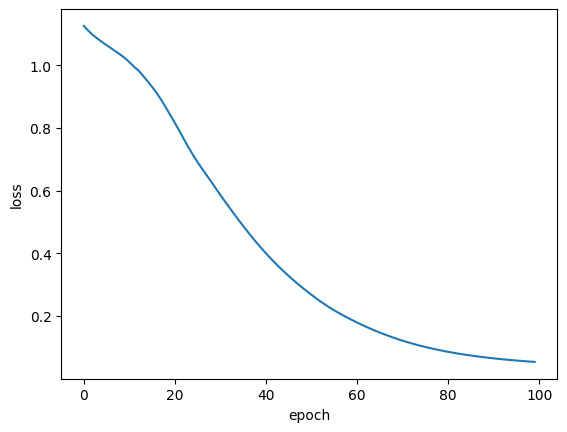

In [262]:
# Graph of the losses
plt.plot(range(epoch), losses)
plt.ylabel('loss')
plt.xlabel('epoch')



```
# The downward graph shows that we are learning
```



In [269]:
# Evaluate Model on the Test Data Set(validate model on the test dataset)
#To do that we need to turn off backwards propagation
with torch.no_grad():  #Basically turn off propagation
  y_eval = model.forward(X_test)  #Find the loss or error
  loss = criterion(y_eval, y_test)  # Measure the error


In [270]:
loss

tensor(0.1315)

In [280]:
#see how the network did on test data against the actual training data
correct = 0
with torch.no_grad():
  for i, data in enumerate(X_test):
    y_val = model.forward(data)


    if y_test[i] ==0:
      x = 'Setosa'
    elif y_test[i] ==1:
      x = 'Versicolor'
    else:
      x = 'Virginica'

    # Will tell us what type of flower class our networ thinks it is
    print(f'{i+1}.) {str(y_val)} \t {x}')

    # correct or not
    if y_val.argmax().item() == y_test[i]:
      correct += 1

print(f'\n{correct} out of {len(y_test)} = {100*correct/len(y_test):.2f}% correct')

1.) tensor([-5.8760,  4.4628,  6.5124]) 	 Virginica
2.) tensor([-7.5436,  4.1670,  9.7255]) 	 Virginica
3.) tensor([-8.4504,  5.1271, 10.1987]) 	 Virginica
4.) tensor([-4.3398,  5.6267,  2.5608]) 	 Versicolor
5.) tensor([-7.1825,  4.8754,  8.2992]) 	 Virginica
6.) tensor([-3.3974,  5.3463,  1.2803]) 	 Versicolor
7.) tensor([-5.9231,  4.9822,  5.9997]) 	 Virginica
8.) tensor([-4.2881,  5.7003,  2.3889]) 	 Versicolor
9.) tensor([-6.5356,  4.9257,  7.1260]) 	 Virginica
10.) tensor([-8.0509,  4.4129, 10.3286]) 	 Virginica
11.) tensor([-5.6762,  4.9500,  5.6215]) 	 Virginica
12.) tensor([ 4.5662, -2.2476, -2.8911]) 	 Setosa
13.) tensor([ 4.2571, -1.9967, -2.7330]) 	 Setosa
14.) tensor([-2.1108,  4.0515,  0.5799]) 	 Versicolor
15.) tensor([ 3.4575, -1.2098, -2.3514]) 	 Setosa
16.) tensor([-5.4724,  5.1165,  5.0934]) 	 Virginica
17.) tensor([ 4.0557, -1.7949, -2.6492]) 	 Setosa
18.) tensor([-5.8075,  4.6053,  6.2458]) 	 Versicolor
19.) tensor([ 4.4343, -2.1392, -2.8242]) 	 Setosa
20.) tensor(

In [281]:
# Evaluate new data on  the network
new_iris = torch.tensor([4.7,3.2,1.3,0.2])


In [282]:
with torch.no_grad():
  print(model(new_iris))

tensor([ 4.5365, -2.2383, -2.8684])


In [283]:
# Save  our NN Model
torch.save(model.state_dict(), 'iris_model.pt')

In [284]:
# Load the Saved Model
new_model = Model()
new_model.load_state_dict(torch.load('iris_model.pt'))

<All keys matched successfully>

In [285]:
# Make sure it loaded correctly
new_model.eval()

Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)